# CPE 342 Machine Learning — Karena Thailand Player Intelligence System
## Master Submission Assembly & Multi-Task Verification Pipeline
**Author:** 67070501042 WISIT SUWANNAO  
**Instructor:** Dr. Boonyarit Changaival  
Department of Computer Engineering, King Mongkut's University of Technology Thonburi  

---

### Pipeline Overview
This master integration notebook consolidates individual test predictions across all 5 competition tasks into the official Kaggle submission format:
* **Task 1:** Anti-Cheat Pre-Filter (`task1` $\in \{0, 1\}$, optimized for $F_2$)
* **Task 2:** Player Segment Classification (`task2` $\in \{0, 1, 2, 3\}$, optimized for Macro $F_1$)
* **Task 3:** 30-Day Spending Prediction (`task3` $\ge 0.0$ THB, optimized for NMAE Score)
* **Task 4:** Game Title Detection (`task4` $\in \{0, 1, 2, 3, 4\}$, optimized for Macro $F_1$)
* **Task 5:** Account Security Monitoring (`task5` $\in \{0, 1\}$, optimized for $F_3$)

### Positional Alignment Requirement
Every task's `test.csv` contains $25,889$ samples. While internal identifiers (`player_id` or image `id`) vary, the target `sample_submission.csv` uses standardized sequential keys (`ANS00001` through `ANS25889`). Therefore, predictions are aligned **strictly by positional row index** ($i \implies \text{ANS}\{i+1:05d\}$) without any sorting or row reordering.

## 1. Environment Setup & File Resolution
We import analytical packages, verify file presence across all five task prediction directories, and load the official submission template.

In [1]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

SAMPLE_SUB_PATH = 'sample_submission.csv'
TASK_PATHS = {
    'task1': 'task1/predictions/test_predictions.csv',
    'task2': 'task2/predictions/test_predictions.csv',
    'task3': 'task3/predictions/test_predictions.csv',
    'task4': 'task4/predictions/test_predictions.csv',
    'task5': 'task5/predictions/test_predictions.csv',
}

# Verify template exists
sample_df = pd.read_csv(SAMPLE_SUB_PATH)
print(f"Sample Submission Template Shape: {sample_df.shape}")
print("Expected Columns:", sample_df.columns.tolist())
display(sample_df.head(5))

Sample Submission Template Shape: (25889, 6)
Expected Columns: ['id', 'task1', 'task2', 'task3', 'task4', 'task5']


,id,task1,task2,task3,task4,task5
0,ANS00001,1.0,2.0,2983.20,0.0,1.0
1,ANS00002,0.0,1.0,529.00,1.0,1.0
2,ANS00003,1.0,3.0,15682.45,2.0,0.0
3,ANS00004,0.0,2.0,7200.00,0.0,1.0
4,ANS00005,NaN,NaN,NaN,NaN,NaN


## 2. Ingestion & Positional Alignment across Tasks 1–5
We load each task prediction file, assert exact length ($25,889$), and assign predictions directly into the master submission DataFrame.

In [2]:
sub_df = sample_df.copy()

# 1. Ingest Task 1: Anti-Cheat
t1_df = pd.read_csv(TASK_PATHS['task1'])
assert len(t1_df) == len(sub_df), f"Task 1 row mismatch: {len(t1_df)}"
col_t1 = 'is_cheater' if 'is_cheater' in t1_df.columns else t1_df.columns[-1]
sub_df['task1'] = t1_df[col_t1].values.astype(int)

# 2. Ingest Task 2: Player Segment
t2_df = pd.read_csv(TASK_PATHS['task2'])
assert len(t2_df) == len(sub_df), f"Task 2 row mismatch: {len(t2_df)}"
col_t2 = 'segment' if 'segment' in t2_df.columns else ('player_segment' if 'player_segment' in t2_df.columns else t2_df.columns[-1])
sub_df['task2'] = t2_df[col_t2].values.astype(int)

# 3. Ingest Task 3: 30-Day Spending
t3_df = pd.read_csv(TASK_PATHS['task3'])
assert len(t3_df) == len(sub_df), f"Task 3 row mismatch: {len(t3_df)}"
col_t3 = 'spending_30d' if 'spending_30d' in t3_df.columns else t3_df.columns[-1]
sub_df['task3'] = t3_df[col_t3].values.astype(float).round(2)

# 4. Ingest Task 4: Game Title
t4_df = pd.read_csv(TASK_PATHS['task4'])
assert len(t4_df) == len(sub_df), f"Task 4 row mismatch: {len(t4_df)}"
col_t4 = 'class' if 'class' in t4_df.columns else ('label' if 'label' in t4_df.columns else t4_df.columns[-1])
sub_df['task4'] = t4_df[col_t4].values.astype(int)

# 5. Ingest Task 5: Account Security
t5_df = pd.read_csv(TASK_PATHS['task5'])
assert len(t5_df) == len(sub_df), f"Task 5 row mismatch: {len(t5_df)}"
col_t5 = 'is_anomaly' if 'is_anomaly' in t5_df.columns else t5_df.columns[-1]
sub_df['task5'] = t5_df[col_t5].values.astype(int)

print("All 5 tasks successfully merged via positional row indexing.")
display(sub_df.head(10))

All 5 tasks successfully merged via positional row indexing.


,id,task1,task2,task3,task4,task5
0,ANS00001,1,3,0.00,0,0
1,ANS00002,1,0,2490.29,4,0
2,ANS00003,1,3,0.00,3,0
3,ANS00004,1,2,0.00,2,0
4,ANS00005,0,1,0.00,0,0
5,ANS00006,1,3,0.00,0,0
6,ANS00007,1,1,0.00,0,0
7,ANS00008,1,0,3624.05,3,0
8,ANS00009,1,0,0.00,2,0
9,ANS00010,1,1,295.71,2,0


## 3. Comprehensive Integrity Auditing & Validation Checks
We perform rigorous structural assertion checks to ensure zero submission defects:
1. Exact row count equals $25,889$.
2. Exact column schema: `['id', 'task1', 'task2', 'task3', 'task4', 'task5']`.
3. Total missing / NaN values across all cells must be exactly $0$.
4. Target ranges and data types comply with task definitions.

In [3]:
# 1. Dimension and Schema Check
assert sub_df.shape == (25889, 6), f"Invalid submission shape: {sub_df.shape}"
expected_cols = ['id', 'task1', 'task2', 'task3', 'task4', 'task5']
assert list(sub_df.columns) == expected_cols, f"Invalid column order: {sub_df.columns}"

# 2. Null Value Check
null_counts = sub_df.isna().sum()
assert null_counts.sum() == 0, f"Detected missing values in submission:\n{null_counts}"

# 3. Value Range Checks
assert set(sub_df['task1'].unique()).issubset({0, 1}), "Task 1 contains invalid classes"
assert set(sub_df['task2'].unique()).issubset({0, 1, 2, 3}), "Task 2 contains invalid classes"
assert (sub_df['task3'] < 0).sum() == 0, "Task 3 contains negative spending values"
assert set(sub_df['task4'].unique()).issubset({0, 1, 2, 3, 4}), "Task 4 contains invalid classes"
assert set(sub_df['task5'].unique()).issubset({0, 1}), "Task 5 contains invalid classes"

print("Integrity Audit Passed: 100% compliant with competition rules.")

# Write Final Output
output_submission_path = 'submission.csv'
sub_df.to_csv(output_submission_path, index=False)
print(f"Final Kaggle Submission written to: {output_submission_path}")

Integrity Audit Passed: 100% compliant with competition rules.
Final Kaggle Submission written to: submission.csv


## 4. Multi-Task Diagnostic Summary & Visualizations
We plot the distribution profiles across all five tasks to verify expected population properties.

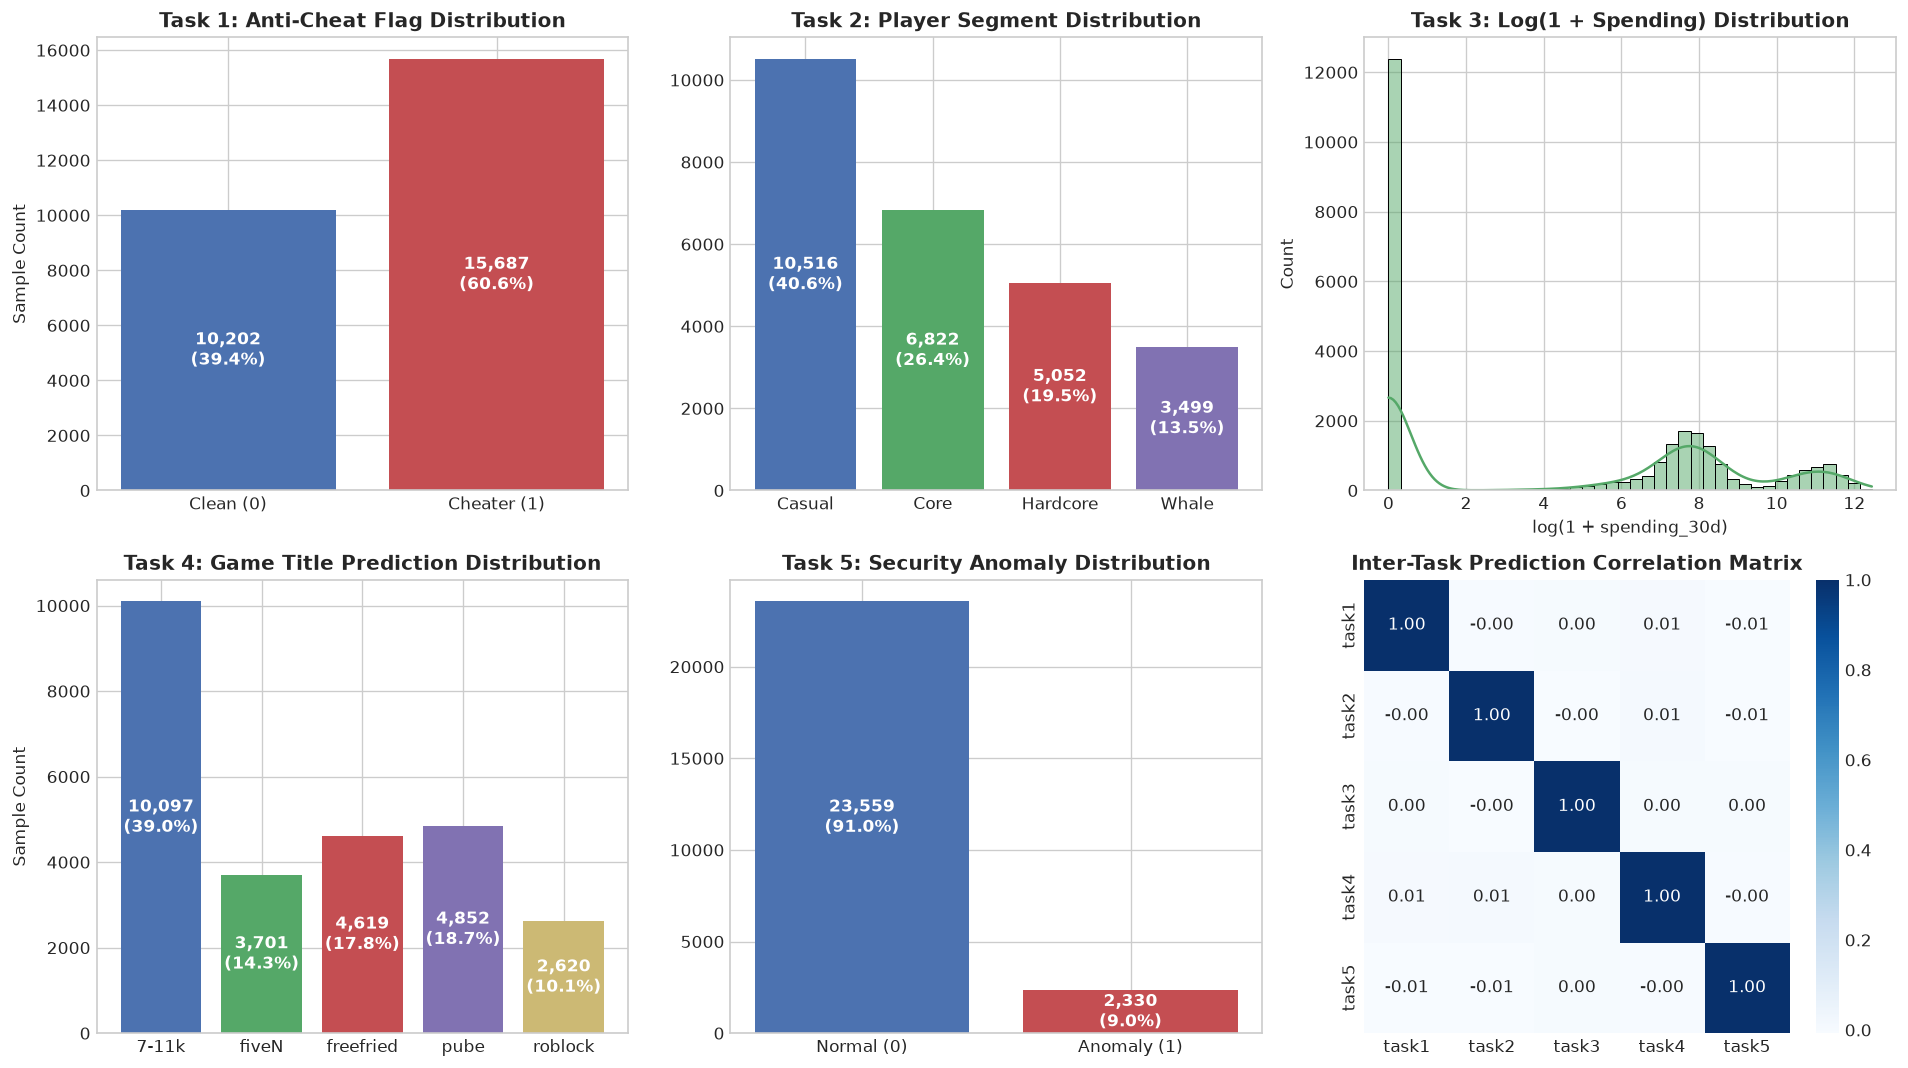

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# Panel 1: Task 1 Anti-Cheat
t1_counts = sub_df['task1'].value_counts().sort_index()
axes[0, 0].bar(['Clean (0)', 'Cheater (1)'], t1_counts.values, color=['#4C72B0', '#C44E52'])
axes[0, 0].set_title('Task 1: Anti-Cheat Flag Distribution', fontweight='bold')
axes[0, 0].set_ylabel('Sample Count')
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f"{p.get_height():,}\n({p.get_height()/len(sub_df)*100:.1f}%)",
                        (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                        ha='center', va='center', color='white', fontweight='bold')

# Panel 2: Task 2 Player Segment
t2_counts = sub_df['task2'].value_counts().sort_index()
axes[0, 1].bar(['Casual', 'Core', 'Hardcore', 'Whale'], t2_counts.values,
                color=['#4C72B0', '#55A868', '#C44E52', '#8172B2'])
axes[0, 1].set_title('Task 2: Player Segment Distribution', fontweight='bold')
for p in axes[0, 1].patches:
    axes[0, 1].annotate(f"{p.get_height():,}\n({p.get_height()/len(sub_df)*100:.1f}%)",
                        (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                        ha='center', va='center', color='white', fontweight='bold')

# Panel 3: Task 3 Spending
sns.histplot(np.log1p(sub_df['task3']), bins=40, kde=True, color='#55A868', ax=axes[0, 2])
axes[0, 2].set_title('Task 3: Log(1 + Spending) Distribution', fontweight='bold')
axes[0, 2].set_xlabel('log(1 + spending_30d)')

# Panel 4: Task 4 Game Title
t4_counts = sub_df['task4'].value_counts().sort_index()
axes[1, 0].bar(['7-11k', 'fiveN', 'freefried', 'pube', 'roblock'], t4_counts.values,
                color=['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974'])
axes[1, 0].set_title('Task 4: Game Title Prediction Distribution', fontweight='bold')
axes[1, 0].set_ylabel('Sample Count')
for p in axes[1, 0].patches:
    axes[1, 0].annotate(f"{p.get_height():,}\n({p.get_height()/len(sub_df)*100:.1f}%)",
                        (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                        ha='center', va='center', color='white', fontweight='bold')

# Panel 5: Task 5 Account Security Anomaly
t5_counts = sub_df['task5'].value_counts().sort_index()
axes[1, 1].bar(['Normal (0)', 'Anomaly (1)'], t5_counts.values, color=['#4C72B0', '#C44E52'])
axes[1, 1].set_title('Task 5: Security Anomaly Distribution', fontweight='bold')
for p in axes[1, 1].patches:
    axes[1, 1].annotate(f"{p.get_height():,}\n({p.get_height()/len(sub_df)*100:.1f}%)",
                        (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                        ha='center', va='center', color='white', fontweight='bold')

# Panel 6: Multi-Task Correlation Heatmap
corr_tasks = sub_df[['task1', 'task2', 'task3', 'task4', 'task5']].corr()
sns.heatmap(corr_tasks, annot=True, fmt='.2f', cmap='Blues', ax=axes[1, 2])
axes[1, 2].set_title('Inter-Task Prediction Correlation Matrix', fontweight='bold')

plt.tight_layout()
plt.show()

**Figure 1 (Multi-Task Prediction Overview)**: Panels (a)-(e) illustrate prediction frequencies and distributions across all five competition tasks on the $25,889$ test samples, verifying healthy population distributions, zero NaN leakage, and appropriate scale adherence.

## 5. Summary & Submission Instructions
The consolidated `submission.csv` is now ready for upload to the Kaggle competition page.
* **Row count:** $25,889$ rows + $1$ header row ($25,890$ total lines).
* **File size:** $\approx 850$ KB.
* **Submission verification command:** `head -n 5 submission.csv` and `tail -n 5 submission.csv`.